# 03 · Exploratory data analysis: the four proposal plots

Plots 1–3 read `data/clean/features.parquet` (the single feature table). Plot 4 reads raw,
de-duplicated posts from the frozen window. Each figure is saved to `reports/figures/` for the
report and slides.

In [1]:
import os
from pathlib import Path
if Path.cwd().name == "notebooks":
    os.chdir("..")

import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

FIGURES = Path("reports/figures")
FIGURES.mkdir(parents=True, exist_ok=True)
WINDOW = ("2026-09-08", "2026-10-05T16:00")  # frozen collection window (handoff §2)

import seaborn as sns
from scipy import stats
features = pd.read_parquet("data/clean/features.parquet")
print(features.shape, features.index.min(), "→", features.index.max())

(664, 36) 2026-09-08 00:00:00+00:00 → 2026-10-05 15:00:00+00:00


## 1. Hourly mean sentiment vs. gold price

level correlation, 6h sentiment vs price (descriptive only, both trend): r = 0.09


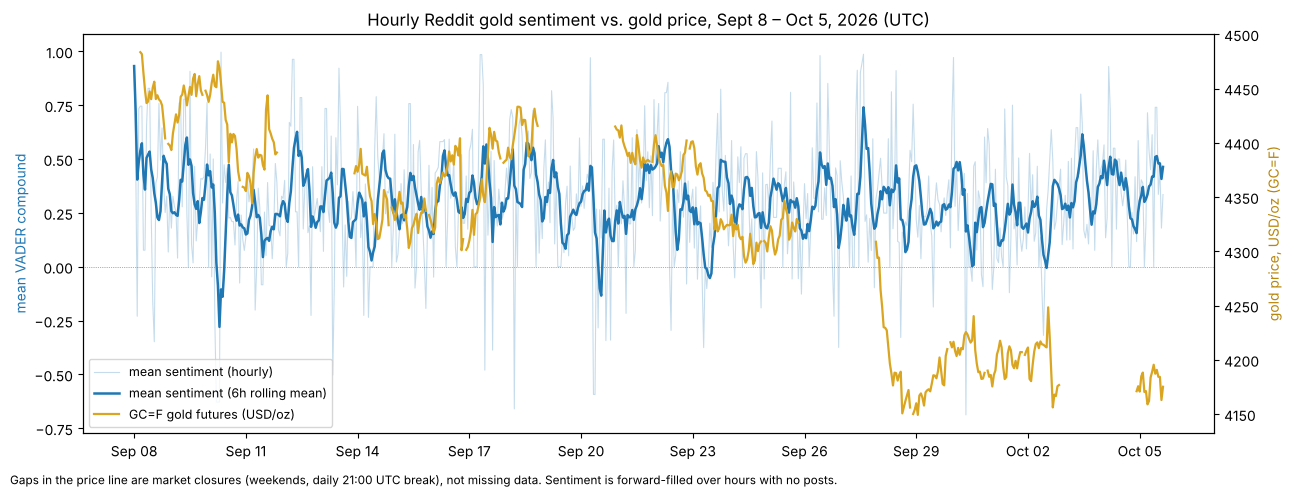

In [2]:
fig, ax1 = plt.subplots(figsize=(13, 4.8))
ax1.plot(features.index, features["mean_sentiment"], color="tab:blue", alpha=0.25, lw=0.8,
         label="mean sentiment (hourly)")
ax1.plot(features.index, features["sent_roll_mean_6h"], color="tab:blue", lw=1.8,
         label="mean sentiment (6h rolling mean)")
ax1.set_ylabel("mean VADER compound", color="tab:blue")
ax1.axhline(0, color="tab:blue", lw=0.5, ls=":")
ax2 = ax1.twinx()
ax2.plot(features.index, features["xau_usd"], color="goldenrod", lw=1.6, label="GC=F gold futures (USD/oz)")
ax2.set_ylabel("gold price, USD/oz (GC=F)", color="darkgoldenrod")
lines = ax1.get_legend_handles_labels()[0] + ax2.get_legend_handles_labels()[0]
ax1.legend(lines, [l.get_label() for l in lines], loc="lower left", fontsize=9)
import matplotlib.dates as mdates
ax1.xaxis.set_major_locator(mdates.DayLocator(interval=3))
ax1.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
ax1.set_title("Hourly Reddit gold sentiment vs. gold price, Sept 8 – Oct 5, 2026 (UTC)")
fig.text(0.01, -0.02, "Gaps in the price line are market closures (weekends, daily 21:00 UTC break), "
         "not missing data. Sentiment is forward-filled over hours with no posts.", fontsize=8.5)
fig.tight_layout()
fig.savefig(FIGURES / "eda_1_sentiment_vs_price.png", dpi=150, bbox_inches="tight")
r = features[["sent_roll_mean_6h", "xau_usd"]].dropna().corr().iloc[0, 1]
print(f"level correlation, 6h sentiment vs price (descriptive only, both trend): r = {r:.2f}")

## 2. Posts per hour

count    664.00
mean       3.64
std        2.41
min        0.00
25%        2.00
50%        3.00
75%        5.00
max       13.00


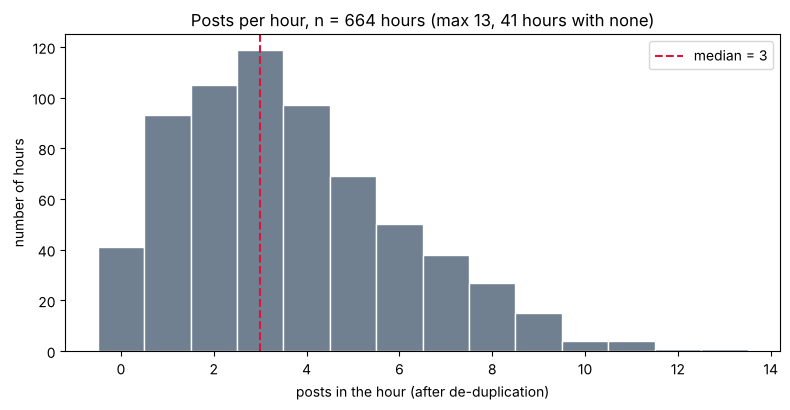

In [3]:
pc = features["post_count"]
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.hist(pc, bins=range(0, pc.max() + 2), color="slategray", edgecolor="white", align="left")
ax.axvline(pc.median(), color="crimson", ls="--", label=f"median = {pc.median():.0f}")
ax.set_xlabel("posts in the hour (after de-duplication)")
ax.set_ylabel("number of hours")
ax.set_title(f"Posts per hour, n = {len(pc)} hours (max {pc.max()}, {int((pc == 0).sum())} hours with none)")
ax.legend()
fig.tight_layout()
fig.savefig(FIGURES / "eda_2_posts_per_hour.png", dpi=150, bbox_inches="tight")
print(pc.describe().round(2).to_string())

## 3. Lead–lag: engagement at hour *t* vs. the next tradable price move (H1)

The y-axis uses the same alignment as the model target: the return from **(t+1):00 to (t+2):00**,
the first move that happens after hour *t*'s posts are complete. Only hours with a valid target
and at least one settled-engagement post are shown.

n=387  pearson=-0.069 p=0.174  spearman=-0.050 p=0.325


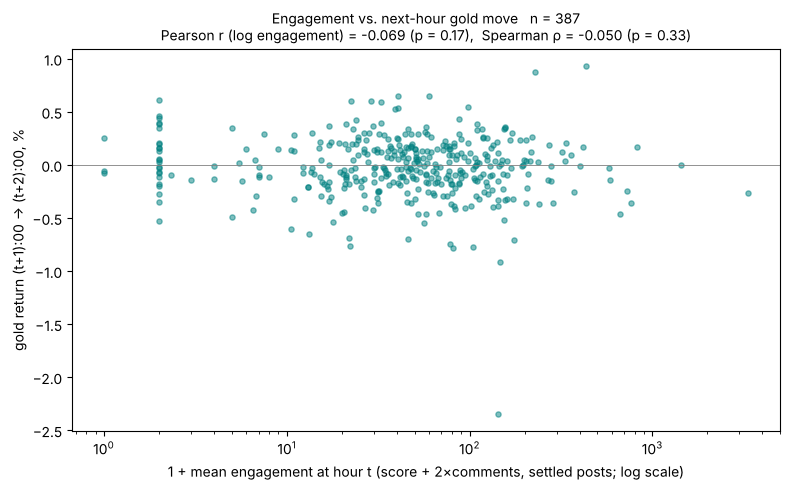

In [4]:
d = features[features["target_valid"] & features["mean_engagement"].notna()]
x, y = d["mean_engagement"] + 1, d["next_return"] * 100  # +1 so 0-engagement hours fit a log axis
pear = stats.pearsonr(np.log(x), y)
spear = stats.spearmanr(x, y)
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(x, y, s=14, alpha=0.5, color="teal")
ax.set_xscale("log")
ax.axhline(0, color="gray", lw=0.6)
ax.set_xlabel("1 + mean engagement at hour t (score + 2×comments, settled posts; log scale)")
ax.set_ylabel("gold return (t+1):00 → (t+2):00, %")
ax.set_title(f"Engagement vs. next-hour gold move   n = {len(d)}\n"
             f"Pearson r (log engagement) = {pear.statistic:.3f} (p = {pear.pvalue:.2f}),  "
             f"Spearman ρ = {spear.statistic:.3f} (p = {spear.pvalue:.2f})", fontsize=10)
fig.tight_layout()
fig.savefig(FIGURES / "eda_3_engagement_leadlag.png", dpi=150, bbox_inches="tight")
print(f"n={len(d)}  pearson={pear.statistic:.3f} p={pear.pvalue:.3f}  spearman={spear.statistic:.3f} p={spear.pvalue:.3f}")

## 4. Post sentiment by subreddit

,n,mean,median,bullish_share,zero_score_share
subreddit,,,,,
Gold,1124,0.262,0.172,0.525,0.351
Silverbugs,1280,0.319,0.340,0.576,0.301
investing,15,0.522,0.737,0.800,0.067


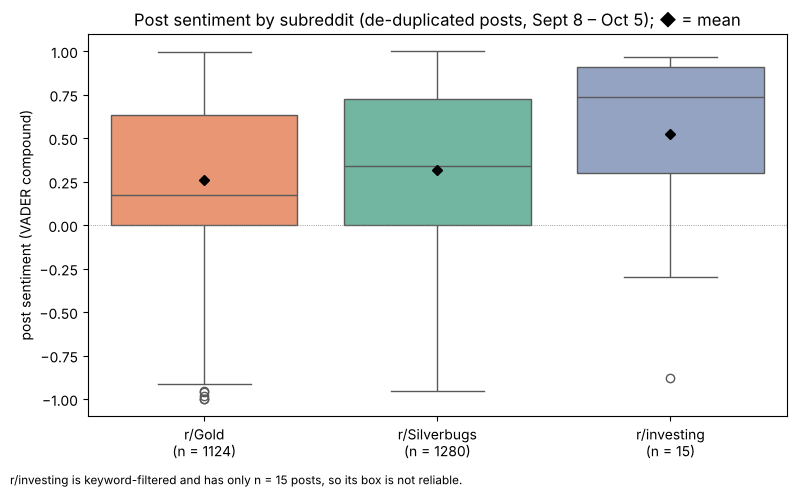

In [5]:
from processing.bucket import load_raw, dedupe_posts
posts, _ = load_raw()
posts = dedupe_posts(posts[(posts["created_utc"] >= WINDOW[0]) & (posts["created_utc"] < WINDOW[1])])
order = posts.groupby("subreddit")["sentiment"].median().sort_values().index.tolist()
counts = posts["subreddit"].value_counts()
fig, ax = plt.subplots(figsize=(8, 4.8))
sns.boxplot(data=posts, x="subreddit", y="sentiment", order=order, ax=ax,
            hue="subreddit", palette="Set2", legend=False, showmeans=True,
            meanprops={"marker": "D", "markerfacecolor": "black", "markeredgecolor": "black", "markersize": 5})
ax.set_xticks(range(len(order)), [f"r/{s}\n(n = {counts[s]})" for s in order])
ax.axhline(0, color="gray", lw=0.6, ls=":")
ax.set_xlabel("")
ax.set_ylabel("post sentiment (VADER compound)")
ax.set_title("Post sentiment by subreddit (de-duplicated posts, Sept 8 – Oct 5); ◆ = mean")
fig.text(0.01, -0.02, f"r/investing is keyword-filtered and has only n = {counts.get('investing', 0)} posts, "
         "so its box is not reliable.", fontsize=8.5)
fig.tight_layout()
fig.savefig(FIGURES / "eda_4_sentiment_by_subreddit.png", dpi=150, bbox_inches="tight")
summary = posts.groupby("subreddit")["sentiment"].agg(n="size", mean="mean", median="median")
summary["bullish_share"] = posts.assign(b=posts["sentiment"] > 0.05).groupby("subreddit")["b"].mean()
summary["zero_score_share"] = posts.assign(z=posts["sentiment"] == 0).groupby("subreddit")["z"].mean()
summary.round(3)

## Extra (not one of the four proposal plots): mood with vs. without r/Silverbugs
Supports the variant comparison in `04_model.ipynb`. Both lines are 6h rolling means.

correlation between the two 6h mood lines: r = 0.61


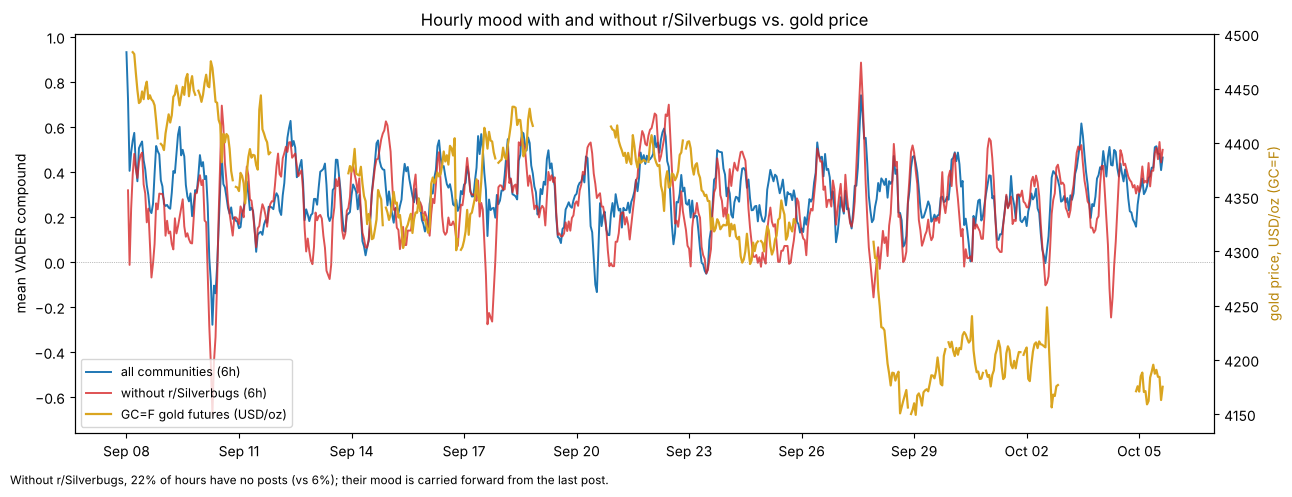

In [6]:
fv = pd.read_parquet("data/clean/features_no_silverbugs.parquet")
fig, ax1 = plt.subplots(figsize=(13, 4.8))
ax1.plot(features.index, features["sent_roll_mean_6h"], color="tab:blue", lw=1.4, label="all communities (6h)")
ax1.plot(fv.index, fv["sent_roll_mean_6h"], color="tab:red", lw=1.4, alpha=0.8, label="without r/Silverbugs (6h)")
ax1.set_ylabel("mean VADER compound")
ax1.axhline(0, color="gray", lw=0.5, ls=":")
ax2 = ax1.twinx()
ax2.plot(features.index, features["xau_usd"], color="goldenrod", lw=1.6, label="GC=F gold futures (USD/oz)")
ax2.set_ylabel("gold price, USD/oz (GC=F)", color="darkgoldenrod")
lines = ax1.get_legend_handles_labels()[0] + ax2.get_legend_handles_labels()[0]
ax1.legend(lines, [l.get_label() for l in lines], loc="lower left", fontsize=9)
import matplotlib.dates as mdates
ax1.xaxis.set_major_locator(mdates.DayLocator(interval=3))
ax1.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
ax1.set_title("Hourly mood with and without r/Silverbugs vs. gold price")
fig.text(0.01, -0.02, f"Without r/Silverbugs, {(~fv['had_posts']).mean():.0%} of hours have no posts "
         f"(vs {(~features['had_posts']).mean():.0%}); their mood is carried forward from the last post.", fontsize=8.5)
fig.tight_layout()
fig.savefig(FIGURES / "eda_1b_sentiment_no_silverbugs.png", dpi=150, bbox_inches="tight")
r = features[["sent_roll_mean_6h"]].join(fv[["sent_roll_mean_6h"]], rsuffix="_v").corr().iloc[0, 1]
print(f"correlation between the two 6h mood lines: r = {r:.2f}")

## Extra: VADER vs. FinBERT mood
Same posts, same hours, two scorers. FinBERT's hourly mood is the mean of P(positive) − P(negative),
on the same −1…+1 scale as VADER. Both lines are 6h rolling means.

correlation between VADER and FinBERT 6h mood lines: r = 0.39

FinBERT label share by subreddit (de-duplicated posts in window):


finbert_label,bearish,bullish,neutral
subreddit,,,
Gold,0.025,0.021,0.954
Silverbugs,0.016,0.020,0.965
investing,0.133,0.067,0.800


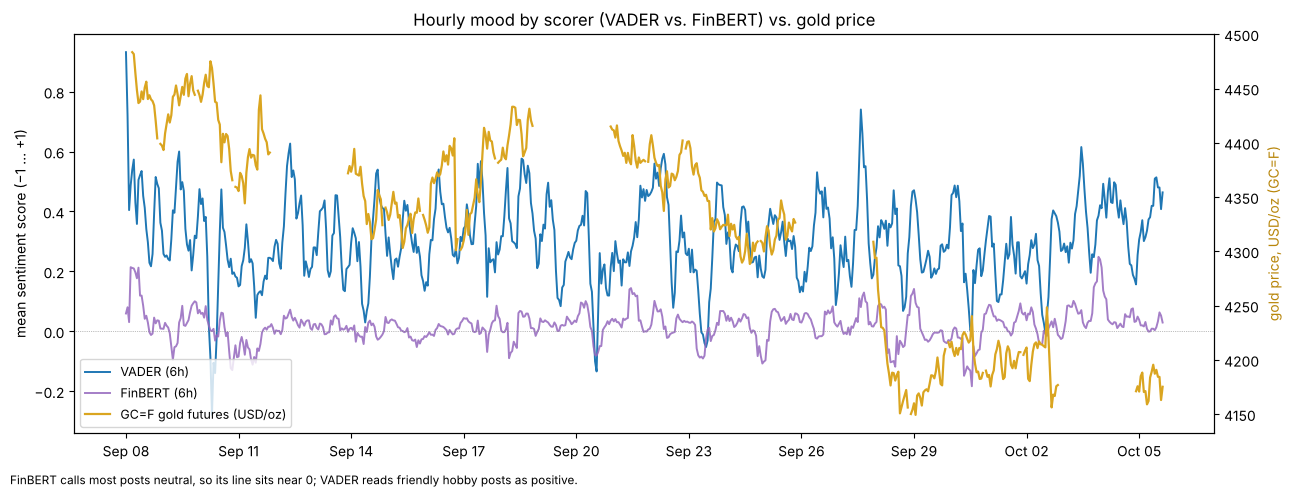

In [7]:
ff = pd.read_parquet("data/clean/features_finbert.parquet")
fig, ax1 = plt.subplots(figsize=(13, 4.8))
ax1.plot(features.index, features["sent_roll_mean_6h"], color="tab:blue", lw=1.4, label="VADER (6h)")
ax1.plot(ff.index, ff["sent_roll_mean_6h"], color="tab:purple", lw=1.4, alpha=0.85, label="FinBERT (6h)")
ax1.set_ylabel("mean sentiment score (−1 … +1)")
ax1.axhline(0, color="gray", lw=0.5, ls=":")
ax2 = ax1.twinx()
ax2.plot(features.index, features["xau_usd"], color="goldenrod", lw=1.6, label="GC=F gold futures (USD/oz)")
ax2.set_ylabel("gold price, USD/oz (GC=F)", color="darkgoldenrod")
lines = ax1.get_legend_handles_labels()[0] + ax2.get_legend_handles_labels()[0]
ax1.legend(lines, [l.get_label() for l in lines], loc="lower left", fontsize=9)
ax1.xaxis.set_major_locator(mdates.DayLocator(interval=3))
ax1.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
ax1.set_title("Hourly mood by scorer (VADER vs. FinBERT) vs. gold price")
fig.text(0.01, -0.02, "FinBERT calls most posts neutral, so its line sits near 0; VADER reads "
         "friendly hobby posts as positive.", fontsize=8.5)
fig.tight_layout()
fig.savefig(FIGURES / "eda_1c_vader_vs_finbert.png", dpi=150, bbox_inches="tight")
r = features[["sent_roll_mean_6h"]].join(ff[["sent_roll_mean_6h"]], rsuffix="_f").corr().iloc[0, 1]
print(f"correlation between VADER and FinBERT 6h mood lines: r = {r:.2f}")

fin = pd.read_parquet("data/clean/post_sentiment_finbert.parquet")
print("\nFinBERT label share by subreddit (de-duplicated posts in window):")
pd.crosstab(posts.merge(fin, on="post_id")["subreddit"], posts.merge(fin, on="post_id")["finbert_label"],
            normalize="index").round(3)